# 05 - Linear Regression with Stochastic Gradient Descent (SGD)

**Objective:** Fit the same linear model as in notebook 04, but find the weights by *iterative optimisation* instead of the closed-form OLS formula. Study scaling, learning rate and convergence.

**Role in the ML workflow:** *Machine Learning* - a second way of learning the relationship between features and charges, evaluated with the same metrics on the same split.

### Concepts to understand first
* **Gradient descent:** start with guessed weights, measure the error (the *loss*), compute in which direction each weight should move to reduce it (the *gradient*), take a small step that way, repeat. Picture walking downhill in fog by feeling the slope under your feet.
* **Stochastic gradient descent (SGD):** instead of using all rows to compute each step, use **one row (or a small batch) at a time**. Steps are noisier but cheap, which is why SGD scales to huge datasets.
* **Learning rate (`eta0`, `learning_rate`):** the step size. Too large -> overshoot and diverge; too small -> crawl and never arrive. `SGDRegressor` by default *shrinks* the rate as training proceeds (`invscaling`).
* **Iteration / epoch (`max_iter`):** one epoch = one pass over the training data. `max_iter` caps the number of epochs.
* **Convergence (`tol`):** training stops when the loss improves by less than `tol` for several consecutive epochs. If `max_iter` is reached first, scikit-learn emits a `ConvergenceWarning` - a signal that the solution may not be final.
* **OLS vs SGD:** OLS solves for the best weights directly in one calculation (deterministic, no tuning). SGD approaches the same solution step by step; its result depends on scaling, learning rate, number of epochs, random seed and regularisation. On this problem both minimise the same squared-error loss, so SGD *can* match OLS - but only if set up well. It does not automatically perform worse (or better).
* **Why feature scaling matters for gradient methods:** each weight's gradient is proportional to (prediction error) x (feature value). Charges are in the thousands, so errors are large, and a feature such as `age` (18-64) multiplies that error by a big number, making the very first steps enormous - while `children` (0-5) gets much smaller steps. One learning rate cannot suit weights that live on such different scales: it is too big for some and too small for others, and the optimisation can blow up. `StandardScaler` rewrites each numeric feature as `(x - mean) / std`, so all features have mean 0 and spread 1 and updates stay proportionate. OLS does not care (it solves exactly); SGD cares a lot. The scaler is **fitted on training data only**, inside the pipeline.

## Setup

In [1]:
import sys
import warnings
from pathlib import Path

# Make the project root importable so we can use the code in src/.
# (Jupyter's working directory is notebooks/, so the project root is one level up.)
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import SGDRegressor

from src.data_preprocessing import load_clean_data, split_data
from src.evaluate import regression_metrics, evaluate_model
from src.feature_engineering import build_preprocessor
from src.train import build_ols_model, build_sgd_model, SGD_PARAMS

X_train, X_test, y_train, y_test = split_data(load_clean_data())   # same split as notebook 04
print("Reproducible SGD settings:", SGD_PARAMS)

Reproducible SGD settings: {'max_iter': 1000, 'tol': 0.001, 'random_state': 42}


## Part A - Why scaling matters: the same SGD with and without `StandardScaler`

Same data, same model, same settings; the only change is whether numeric features are scaled.

In [3]:
def fit_report(label, model):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        model.fit(X_train, y_train)
    warned = any(issubclass(w.category, ConvergenceWarning) for w in caught)
    m = regression_metrics(y_test, model.predict(X_test))
    return {"Setup": label, "epochs used": model.named_steps["model"].n_iter_,
            "ConvergenceWarning": warned, "Test RMSE": m["RMSE"], "Test R2": m["R2"]}

scaling_comparison = pd.DataFrame([
    fit_report("SGD, numeric features NOT scaled", build_sgd_model(scale_numeric=False)),
    fit_report("SGD, StandardScaler on numeric features", build_sgd_model(scale_numeric=True)),
])
scaling_comparison.round(3)

,Setup,epochs used,ConvergenceWarning,Test RMSE,Test R2
0,"SGD, numeric features NOT scaled",62,False,8.585191e+08,-4.011051e+09
1,"SGD, StandardScaler on numeric features",49,False,5.969719e+03,8.060000e-01


**Result:** without scaling, SGD **diverges completely** (test RMSE of about 8.6 x 10^8 and an R-squared of about -4 x 10^9 - far worse than just predicting the average). With scaling it reaches a test RMSE of about 5,970 and R-squared of about 0.81.

Notice that the unscaled run did **not** raise a `ConvergenceWarning` - it stopped after 62 epochs because the loss stopped changing much, at an absurd value. *The absence of a warning does not mean the model is good.* Always look at the metrics.

## Part B - The SGD model (scaled, reproducible configuration)

`Pipeline`: encode categoricals -> `StandardScaler` on `age`, `bmi`, `children` -> `SGDRegressor(max_iter=1000, tol=1e-3, random_state=42)`. Other parameters keep scikit-learn's defaults (squared-error loss, L2 penalty `alpha=0.0001`, `eta0=0.01`, `learning_rate="invscaling"`) because we have no evidence yet that changing them would help.

In [4]:
sgd_model = build_sgd_model()

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    sgd_model.fit(X_train, y_train)

sgd = sgd_model.named_steps["model"]
print(sgd_model)
print("\nEpochs used (n_iter_):", sgd.n_iter_, "of max_iter =", sgd.max_iter)
print("Convergence warnings :", [str(w.message) for w in caught if issubclass(w.category, ConvergenceWarning)] or "none")

Pipeline(steps=[('preprocess',
                 Pipeline(steps=[('add_features',
                                  FunctionTransformer(func=<function add_engineered_features at 0x7f0187966020>,
                                                      kw_args={'features': ()})),
                                 ('encode_scale',
                                  ColumnTransformer(transformers=[('numeric',
                                                                   StandardScaler(),
                                                                   ['age',
                                                                    'bmi',
                                                                    'children']),
                                                                  ('binary',
                                                                   OneHotEncoder(drop='if_binary'),
                                                                   ['sex',
                           

### Predictions and metrics (same evaluation as OLS)

In [5]:
ols_model = build_ols_model().fit(X_train, y_train)

comparison = pd.concat([
    evaluate_model("OLS", ols_model, X_train, y_train, X_test, y_test),
    evaluate_model("SGD", sgd_model, X_train, y_train, X_test, y_test),
], ignore_index=True)
comparison.round(4)

,Model,Dataset,RMSE,MAE,R2
0,OLS,Training,6081.1069,4181.9015,0.7299
1,OLS,Testing,5956.3429,4177.0456,0.8069
2,SGD,Training,6082.1833,4164.1531,0.7298
3,SGD,Testing,5969.7190,4162.7168,0.8061


In [6]:
# How close are the two models' predictions to each other?
ols_pred, sgd_pred = ols_model.predict(X_test), sgd_model.predict(X_test)
diff = np.abs(ols_pred - sgd_pred)
print(f"Largest absolute difference between OLS and SGD test predictions: {diff.max():,.1f}")
print(f"Average absolute difference                                    : {diff.mean():,.1f}")
print(f"Correlation between the two sets of predictions                : {np.corrcoef(ols_pred, sgd_pred)[0, 1]:.5f}")

Largest absolute difference between OLS and SGD test predictions: 393.0
Average absolute difference                                    : 92.1
Correlation between the two sets of predictions                : 0.99994


**OLS vs SGD (same split, same features):**
* Training RMSE: OLS 6,081.11 vs SGD 6,082.18. Test RMSE: OLS 5,956.34 vs SGD 5,969.72. Test R-squared 0.807 vs 0.806. SGD's test MAE (4,162.7) is actually a little *lower* than OLS's (4,177.0).
* The differences are tiny and go both ways, so neither model is meaningfully better here. The small gaps come from SGD's stochastic path and its default L2 penalty.
* The predictions are almost identical: correlation 0.99994, average difference about 92 (compare with typical errors of about 4,000-6,000). Training took 49 of the 1,000 allowed epochs with no warning.

### Watching SGD learn

The plot shows training RMSE after each epoch (using `partial_fit`, one pass per call; an illustration, not the exact path of `.fit`). The dashed line is the OLS training RMSE, the best any linear model on these features can do on this data.

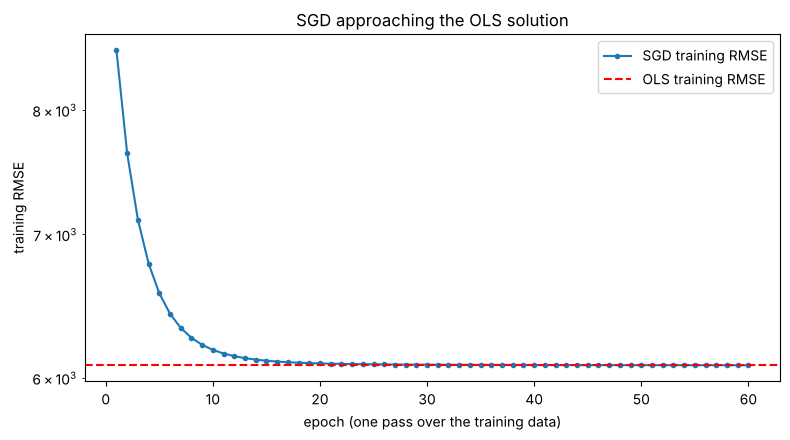

Epoch 1 RMSE: 8530 | epoch 10: 6183 | epoch 60: 6082 | OLS: 6081


In [7]:
pre = build_preprocessor(scale_numeric=True).fit(X_train)       # fitted on training data only
Xt_train = pre.transform(X_train)

ols_train_rmse = regression_metrics(y_train, ols_model.predict(X_train))["RMSE"]
curve_model = SGDRegressor(random_state=42)
epoch_rmse = []
for epoch in range(60):
    curve_model.partial_fit(Xt_train, y_train)
    epoch_rmse.append(regression_metrics(y_train, curve_model.predict(Xt_train))["RMSE"])

plt.figure(figsize=(8, 4.5))
plt.plot(range(1, 61), epoch_rmse, marker="o", markersize=3, label="SGD training RMSE")
plt.axhline(ols_train_rmse, color="red", linestyle="--", label="OLS training RMSE")
plt.xlabel("epoch (one pass over the training data)")
plt.ylabel("training RMSE")
plt.title("SGD approaching the OLS solution")
plt.legend()
plt.yscale("log")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "07_sgd_learning_curve.png", dpi=150, bbox_inches="tight")
plt.show()
print("Epoch 1 RMSE:", round(epoch_rmse[0]), "| epoch 10:", round(epoch_rmse[9]), "| epoch 60:", round(epoch_rmse[-1]), "| OLS:", round(ols_train_rmse))

SGD starts far from the answer (training RMSE about 8,530 after the first epoch), improves quickly (about 6,183 by epoch 10), and by epoch 60 (about 6,082) is within about 1 unit of the OLS training RMSE (about 6,081). Same loss function, same best answer; SGD just walks there instead of jumping straight to it.

## Part C - Investigating learning rate and iterations (convergence)

We deliberately try settings that *should* behave badly, to see what a convergence warning looks like and what it means. All use scaled features and the same data.

In [8]:
configs = {
    "default (eta0=0.01, max_iter=1000)":      {},
    "too few epochs (max_iter=5)":             {"max_iter": 5},
    "tiny learning rate (eta0=1e-5)":          {"eta0": 1e-5},
    "large learning rate (eta0=0.5)":          {"eta0": 0.5},
    "constant rate (eta0=0.01, 'constant')":   {"learning_rate": "constant"},
    "strong regularisation (alpha=100)":       {"alpha": 100},
}
rows = [fit_report(name, build_sgd_model(**params)) for name, params in configs.items()]
convergence_study = pd.DataFrame(rows)
convergence_study.round(3)

,Setup,epochs used,ConvergenceWarning,Test RMSE,Test R2
0,"default (eta0=0.01, max_iter=1000)",49,False,5969.719,0.806
1,too few epochs (max_iter=5),5,True,7105.040,0.725
2,tiny learning rate (eta0=1e-5),1000,True,14435.784,-0.134
3,large learning rate (eta0=0.5),38,False,6010.167,0.803
4,"constant rate (eta0=0.01, 'constant')",11,False,6223.458,0.789
5,strong regularisation (alpha=100),12,False,13608.557,-0.008


| Setting | What happened | Lesson |
|---|---|---|
| default | 49 epochs, no warning, test RMSE about 5,970 | a good starting point once features are scaled |
| `max_iter=5` | **ConvergenceWarning**, test RMSE about 7,105 | stopped too early - the model was still improving, so it underfits |
| `eta0=1e-5` | used all 1,000 epochs, **ConvergenceWarning**, test RMSE about 14,436, R-squared about -0.13 | steps so tiny that even 1,000 epochs are not enough to learn; worse than predicting the mean |
| `eta0=0.5` | 38 epochs, test RMSE about 6,010 | still fine here, because the default `invscaling` schedule shrinks the rate rapidly; a large start is not always fatal |
| `learning_rate="constant"` | 11 epochs, test RMSE about 6,223 | a constant step keeps bouncing around the minimum and stops early at the tolerance, so it is a little worse |
| `alpha=100` | 12 epochs, **no warning**, test RMSE about 13,609, R-squared about -0.01 | an over-strong L2 penalty shrinks the weights toward zero, so the model predicts roughly the average |

So a warning is a useful clue (the first two rows) but the metrics are the real test: the last row performs terribly without any warning. This is the "performance depends on scaling, learning rate, convergence and regularisation" point from the project brief, shown with evidence rather than asserted.

## Summary

* SGD, with scaled features and sensible defaults, reaches essentially the same predictions as OLS on this problem.
* Scaling is not optional for SGD. Without it the optimisation diverges.
* A `ConvergenceWarning` is information: it means the epoch limit was hit before the loss stopped improving. Always check `n_iter_` and the metrics rather than silencing the warning.
* The tuning of learning rate, regularisation and epochs (with cross-validation) is in notebook 06.

## Common errors and fixes
| Problem | Cause | Fix |
|---|---|---|
| Enormous RMSE or `nan` | features not scaled, or learning rate too high | use `StandardScaler`, lower `eta0` |
| `ConvergenceWarning` | `max_iter` reached before `tol` satisfied | inspect `n_iter_` and the metrics; raise `max_iter`, adjust `eta0`, or use `learning_rate="adaptive"` |
| Different result each run | `random_state` not set | set `random_state=42` |
| Scaler fitted on all data | scaling before the split | keep the scaler inside the `Pipeline` |

## Practical task
1. Rebuild the model with `tol=1e-6` and report `n_iter_`. Why does it change?
2. Set `penalty=None` (no regularisation) and compare the test RMSE with the default.
3. In your own words, explain why SGD needs scaled features but OLS does not.

**Next:** notebook 06 - model evaluation, feature experiments and model improvement.